# Fightin' Words: marriage discussions
Compare language in official media articles and Weibo posts, 2021–2025.

## 1. Load the data
Use the `tokens` column from the two analysis CSVs. Run this notebook from the `notebook` folder.

In [1]:
from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

project = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "notebook").is_dir() and (p / "data").is_dir())
data = project / "data"
results = project / "data" / "analysis_results"
results.mkdir(parents=True, exist_ok=True)
(project / "data" / "generated_figures").mkdir(parents=True, exist_ok=True)

official = pd.read_csv(data / "official_media_analysis.csv", usecols=["tokens"], dtype=str).dropna()
weibo = pd.read_csv(data / "weibo_posts_analysis.csv", usecols=["tokens"], dtype=str).dropna()
print(f"Official articles: {len(official):,}; Weibo posts: {len(weibo):,}")


Official articles: 2,020; Weibo posts: 21,945


## 2. Count words
Each preprocessed word in `tokens` counts once per appearance.

In [2]:
official_counts = Counter(word for text in official["tokens"] for word in text.split())
weibo_counts = Counter(word for text in weibo["tokens"] for word in text.split())
print(f"Official tokens: {sum(official_counts.values()):,}; Weibo tokens: {sum(weibo_counts.values()):,}")


Official tokens: 638,678; Weibo tokens: 805,412


## 3. Calculate Fightin' Words
Use the pooled vocabulary as an informative prior. A positive z-score favors official media; a negative score favors Weibo. Keep words used at least 20 times in total.

In [3]:
words = sorted(official_counts.keys() | weibo_counts.keys())
o = np.array([official_counts[w] for w in words], dtype=float)
w = np.array([weibo_counts[x] for x in words], dtype=float)

prior_strength = 1000.0
prior = prior_strength * (o + w) / (o.sum() + w.sum())
o_log_odds = np.log((o + prior) / (o.sum() + prior_strength - o - prior))
w_log_odds = np.log((w + prior) / (w.sum() + prior_strength - w - prior))
z = (o_log_odds - w_log_odds) / np.sqrt(1 / (o + prior) + 1 / (w + prior))

scores = pd.DataFrame({"word": words, "official_count": o.astype(int), "weibo_count": w.astype(int), "z_score": z})
scores["total_count"] = scores["official_count"] + scores["weibo_count"]
scores = scores.loc[scores["total_count"] >= 20].sort_values("z_score", ascending=False).reset_index(drop=True)
print(f"Words compared: {len(scores):,}")


Words compared: 9,049


## 4. View the strongest words
These are differences in word use, not proof of why the groups differ.

In [4]:
top_official = scores.head(20).copy()
top_weibo = scores.tail(20).sort_values("z_score").copy()
print("Official media")
display(top_official[["word", "z_score", "official_count", "weibo_count"]])
print("Weibo")
display(top_weibo[["word", "z_score", "official_count", "weibo_count"]])


Official media


,word,z_score,official_count,weibo_count
0,婚姻登记,58.804783,5819,640
1,彩礼,45.046425,6293,2906
2,办理,35.109472,2424,128
3,服务,35.083625,2974,90
4,活动,34.923957,2282,143
5,结婚登记,32.684529,1864,160
6,法院,32.050485,1764,168
7,登记,31.999655,1721,239
8,青年,31.651544,1861,120
9,新人,31.592248,2084,92


Weibo


,word,z_score,official_count,weibo_count
9048,结婚,-44.635658,3349,10202
9047,喜欢,-40.717985,274,4330
9046,孩子,-37.042721,1020,4617
9045,催婚,-35.322302,224,3223
9044,朋友,-34.017318,362,3018
9043,感觉,-33.465417,224,2865
9042,人生,-28.204515,285,2125
9041,妈妈,-28.027239,130,2056
9040,希望,-27.436992,618,2650
9039,不婚,-25.888151,124,1728


## 5. Save results and make a two-sided chart
Save the word tables. The chart places official media above Weibo, with positive and negative scores on the same scale.

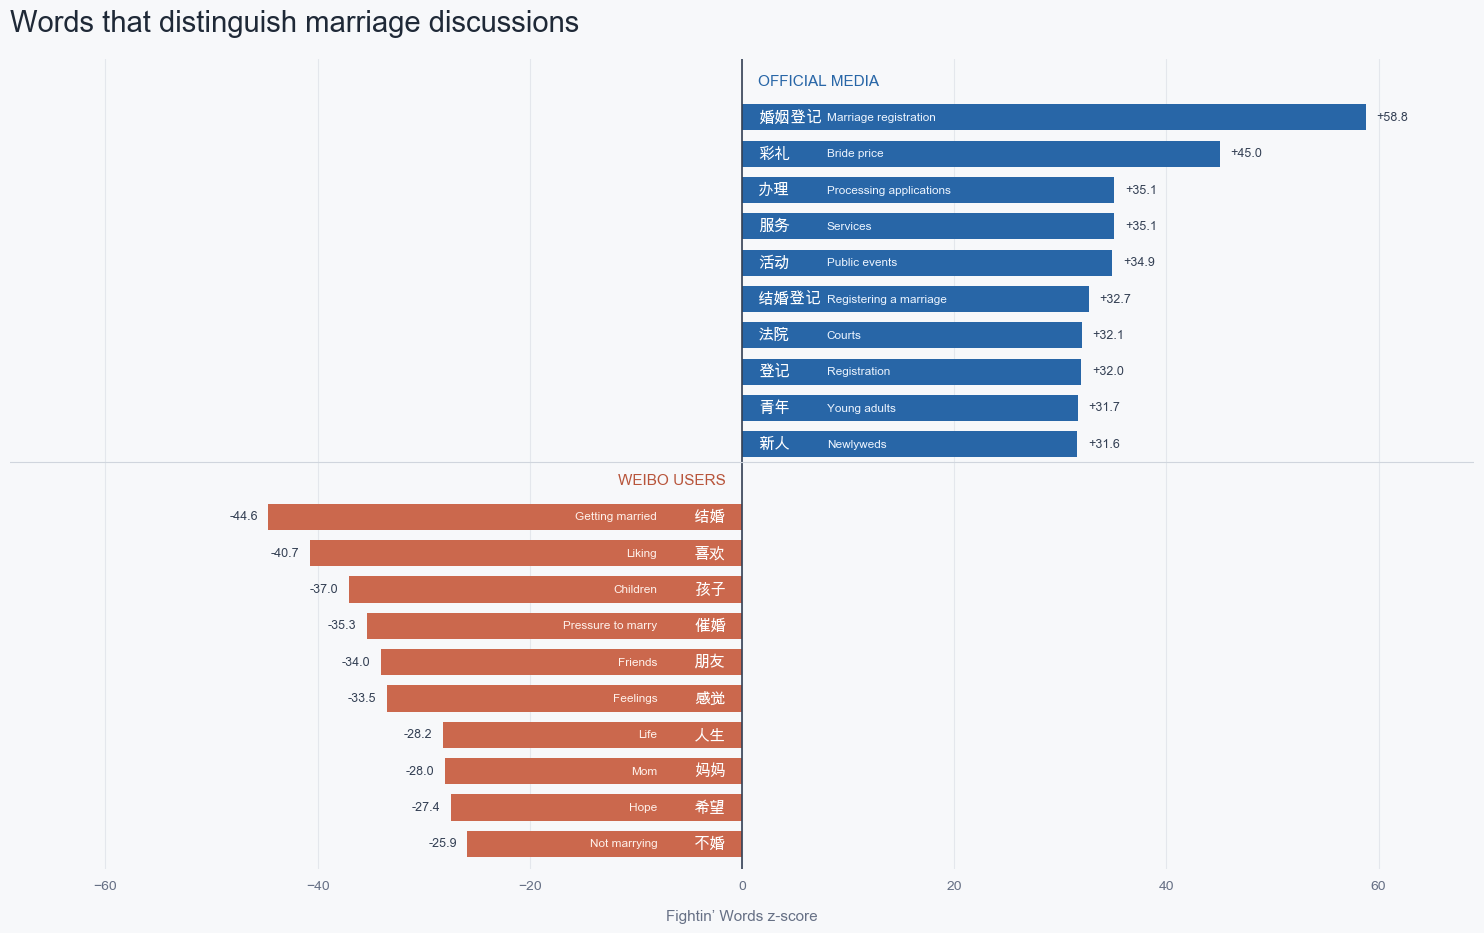

Saved two CSV tables and one chart in: /Users/jingwenzhai/Desktop/Fightin Words/结果


In [5]:
scores.to_csv(results / "fightin_words_scores.csv", index=False, encoding="utf-8-sig")
top = pd.concat([top_official.assign(group="Official media"), top_weibo.assign(group="Weibo")])
top[["group", "word", "z_score", "official_count", "weibo_count", "total_count"]].to_csv(
    results / "fightin_words_top_words.csv", index=False, encoding="utf-8-sig"
)

english = {
    "婚姻登记": "Marriage registration", "彩礼": "Bride price", "办理": "Processing applications",
    "服务": "Services", "活动": "Public events", "结婚登记": "Registering a marriage",
    "法院": "Courts", "登记": "Registration", "青年": "Young adults", "新人": "Newlyweds",
    "结婚": "Getting married", "喜欢": "Liking", "孩子": "Children",
    "催婚": "Pressure to marry", "朋友": "Friends", "感觉": "Feelings",
    "人生": "Life", "妈妈": "Mom", "希望": "Hope", "不婚": "Not marrying",
}

plt.rcParams["font.family"] = "Arial Unicode MS"
fig, ax = plt.subplots(figsize=(16, 10), facecolor="#f7f8fa")
ax.set_facecolor("#f7f8fa")

official_chart = top_official.head(10).reset_index(drop=True)
weibo_chart = top_weibo.head(10).reset_index(drop=True)
official_y = 20 - np.arange(10)
weibo_y = 9 - np.arange(10)
ax.barh(official_y, official_chart["z_score"], height=0.72, color="#2866a7")
ax.barh(weibo_y, weibo_chart["z_score"], height=0.72, color="#cb684d")

for table, positions, side in [(official_chart, official_y, "right"),
                               (weibo_chart, weibo_y, "left")]:
    for row, position in enumerate(positions):
        word = table.loc[row, "word"]
        score = table.loc[row, "z_score"]
        inside_x = 1.5 if side == "right" else -1.5
        align = "left" if side == "right" else "right"
        ax.text(inside_x, position, word, ha=align, va="center",
                fontsize=11.5, fontweight="bold", color="white")
        english_x = 8.0 if side == "right" else -8.0
        ax.text(english_x, position, english[word], ha=align, va="center",
                fontsize=8.5, color="#edf5ff" if side == "right" else "#fff2ec")
        ax.text(score + (1 if side == "right" else -1), position,
                f"{score:+.1f}", ha="left" if side == "right" else "right",
                va="center", fontsize=9, color="#344054")

ax.text(1.5, 21.0, "OFFICIAL MEDIA", ha="left", va="center",
        fontsize=11, fontweight="bold", color="#2866a7")
ax.text(-1.5, 10.0, "WEIBO USERS", ha="right", va="center",
        fontsize=11, fontweight="bold", color="#b8553b")
ax.axvline(0, color="#344054", linewidth=1.2)
ax.axhline(10.5, color="#d0d5dd", linewidth=0.8)
ax.set_xlim(-69, 69)
ax.set_ylim(-0.7, 21.6)
ax.set_yticks([])
ax.set_xticks([-60, -40, -20, 0, 20, 40, 60])
ax.grid(axis="x", color="#e4e7ec", linewidth=0.8)
ax.set_axisbelow(True)
ax.tick_params(axis="x", length=0, labelsize=10, pad=8, colors="#667085")
for spine in ax.spines.values():
    spine.set_visible(False)
ax.set_xlabel("Fightin’ Words z-score", fontsize=11, color="#667085", labelpad=12)
ax.set_title("Words that distinguish marriage discussions", loc="left",
             fontsize=21, fontweight="bold", color="#1f2937", pad=20)
fig.subplots_adjust(left=0.055, right=0.97, top=0.91, bottom=0.10)
fig.savefig((project / "data" / "generated_figures") / "fightin_words_top_words.png", dpi=200, facecolor=fig.get_facecolor())
plt.show()
print("Tables:", results, "Figures:", project / "data" / "generated_figures")
